### Exercice 1 -	K-MEANS SUR DES POINTS EN 2D

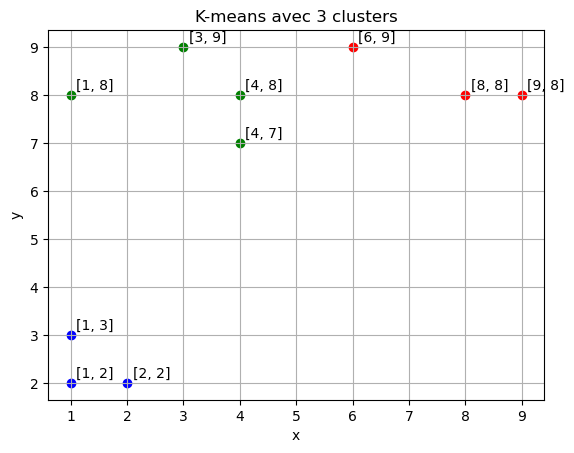

In [51]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Points
points = [
    # À compléter… 
]

# K-means avec 3 clusters
kmeans = # À compléter… 
labels = # À compléter… 

# Visualisation
plt.figure()

colors = #À compléter… 

for i in range(len(points)):
    x = points[i][0]
    y = points[i][1]
    plt.scatter(x, y, color=colors[labels[i]])
    plt.text(x+0.1, y+0.1, str(points[i]))

plt.title("K-means avec 3 clusters")
plt.xlabel("x")
plt.ylabel("y")
plt.grid()
plt.show()

### Exercice 2 -	Clustering de mots avec K-means

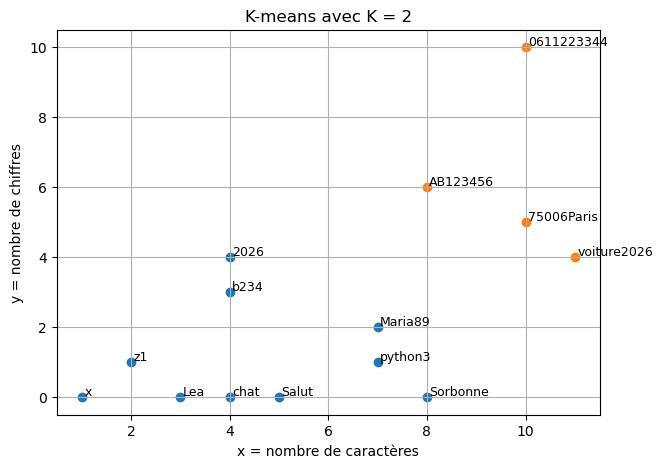

In [40]:
# pip install scikit-learn matplotlib

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Données
words = ["chat", "Sorbonne", "b234", "voiture2026", "Lea", "2026", "75006Paris", "Maria89", "x", "Salut", "z1", "python3", "AB123456", "0611223344"]

# Calcul des points (x, y)
points = []
for w in words:
    x = # À compléter avec le nombre de caractères
    y = # À compléter avec le nombre de chiffres
    points.append([x, y])

# Choisir K ici
K = # À compléter… 

kmeans = # À compléter… 
labels = # À compléter… 

# Visualisation
plt.figure(figsize=(7,5))

# Palette automatique de couleurs
colors = plt.cm.tab10.colors   # jusqu'à 10 couleurs différentes

for i in range(len(points)):
    x = points[i][0]
    y = points[i][1]
    cluster = labels[i]
    
    plt.scatter(x, y, color=colors[cluster])
    plt.text(x + 0.05, y + 0.05, words[i], fontsize=9)

plt.xlabel("x = nombre de caractères")
plt.ylabel("y = nombre de chiffres")
plt.title(f"K-means avec K = {K}")
plt.grid(True)
plt.show()

### Exercice 3 -	Clustering de mini-phrases avec Word Embeddings

In [48]:
#!pip install sentence-transformers scikit-learn

from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
import numpy as np

# Charger un modèle multilingue (meilleur pour le français)
model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")

# Mini-phrases simples
sentences = [
    "Elle adore le chocolat chaud.",
    "J’achète un pain au chocolat.",
    "Je mange un sandwich au jambon et au fromage.",
    "La baguette est croustillante.",
    "La bibliothèque est grande.",
    "La pomme est un fruit sucré.",
    "La Sorbonne est à Paris.",
    "La Sorbonne est une université célèbre.",
    "Le chien court dans le parc.",
    "Le fromage vient de la ferme.",
    "Le lion vit en Afrique.",
    "La baguette est croustillante.",
    "Le pain au chocolat est sucré.",
    "Le poisson nage dans l’eau.",
    "Les algorithmes prennent des décisions.",
    "Les étudiants étudient à la Sorbonne.",
    "L’IA analyse des images.",
    "L’IA apprend à partir des données.",
    "L’oiseau vole dans le ciel.",
    "Python est utilisé en intelligence artificielle.",
    "Un robot utilise l’IA.",
    "Je mange un sandwich au jambon et au fromage.",
    "Une banane est jaune."
]

# Transformer les phrases en vecteurs
X = model.encode(sentences)

# Normaliser (important pour de meilleurs clusters)
X = X / np.linalg.norm(X, axis=1, keepdims=True)

# Appliquer K-means
kmeans = KMeans(n_clusters=4, random_state=0, n_init=10)
labels = kmeans.fit_predict(X)

# Regrouper les phrases par cluster
clusters = {i: [] for i in range(4)}

for sentence, label in zip(sentences, labels):
    clusters[label].append(sentence)

# Affichage
for i in range(4):
    print("\nCluster", i)
    for s in clusters[i]:
        print("-", s)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Cluster 0
- La bibliothèque est grande.
- La Sorbonne est à Paris.
- La Sorbonne est une université célèbre.
- Les étudiants étudient à la Sorbonne.

Cluster 1
- Elle adore le chocolat chaud.
- J’achète un pain au chocolat.
- Je mange un sandwich au jambon et au fromage.
- La baguette est croustillante.
- La pomme est un fruit sucré.
- Le fromage vient de la ferme.
- La baguette est croustillante.
- Le pain au chocolat est sucré.
- Je mange un sandwich au jambon et au fromage.
- Une banane est jaune.

Cluster 2
- Les algorithmes prennent des décisions.
- L’IA analyse des images.
- L’IA apprend à partir des données.
- Python est utilisé en intelligence artificielle.
- Un robot utilise l’IA.

Cluster 3
- Le chien court dans le parc.
- Le lion vit en Afrique.
- Le poisson nage dans l’eau.
- L’oiseau vole dans le ciel.


### Exercice 4 -	K-means avec Word Embeddings + Visualisation (PCA) 

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Dimension des embeddings : (12, 384)

Embeddings des 3 premières phrases :

Phrase : L'ananas est originaire d'Amérique du Sud (Paraguay, nord-est de l'Argentine et sud du Brésil).
10 premières valeurs : [-0.20881009 -0.627567    0.22894734  0.04649259  0.48937362 -0.12914452
 -0.14207895 -0.04210218  0.1520717   0.12865494]
--------------------------------------------------
Phrase : L'hôpital accueille les malades.
10 premières valeurs : [-0.0287902   0.06405738 -0.28273383  0.04773942  0.19467211 -0.26708812
 -0.11046988  0.22689693  0.254368    0.1777806 ]
--------------------------------------------------
Phrase : L'infirmière soigne les malades.
10 premières valeurs : [-0.29304668 -0.10239664 -0.00972352  0.5289502  -0.02425819 -0.00137069
  0.14324957  0.28433186  0.28173316  0.21289547]
--------------------------------------------------


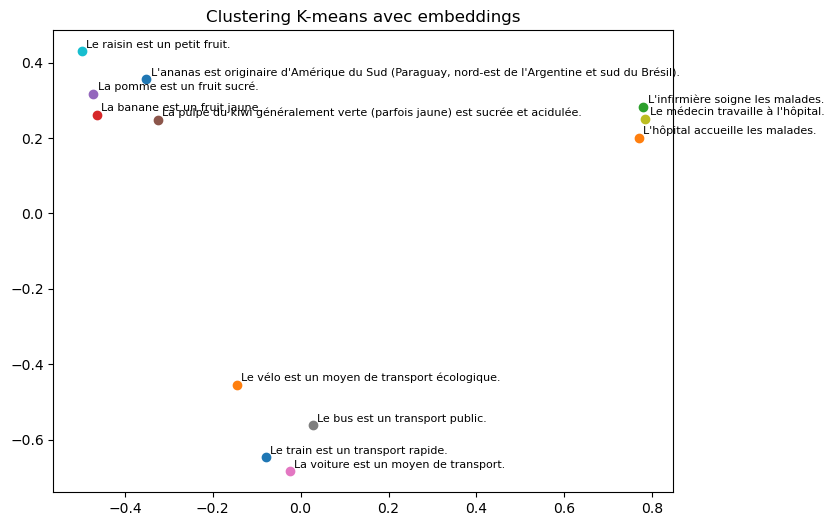

In [52]:
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import numpy as np
import matplotlib.pyplot as plt

# Mini-phrases
sentences = [
    "L'ananas est originaire d'Amérique du Sud (Paraguay, nord-est de l'Argentine et sud du Brésil).",
    "L'hôpital accueille les malades.",
    "L'infirmière soigne les malades.",
    "La banane est un fruit jaune.",
    "La pomme est un fruit sucré.",
    "La pulpe du kiwi généralement verte (parfois jaune) est sucrée et acidulée.",
    "La voiture est un moyen de transport.",
    "Le bus est un transport public.",
    "Le médecin travaille à l'hôpital.",
    "Le raisin est un petit fruit.",
    "Le train est un transport rapide.",
    "Le vélo est un moyen de transport écologique."
]

# Embeddings
model = SentenceTransformer("paraphrase-multilingual-MiniLM-L12-v2")
X = model.encode(sentences)

print("Dimension des embeddings :", X.shape)
print("\nEmbeddings des 3 premières phrases :\n")

for i in range(3):
    print("Phrase :", sentences[i])
    print("10 premières valeurs :", X[i][:10])  # pour ne pas tout afficher
    print("-" * 50)

# Normalisation (important pour KMeans)
X = X / np.linalg.norm(X, axis=1, keepdims=True)

# KMeans
kmeans = KMeans(n_clusters=3, random_state=0, n_init=10)
labels = kmeans.fit_predict(X)

# Réduction en 2D (PCA)
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)

# Visualisation

plt.figure(figsize=(8,6))

for i in range(len(sentences)):
    plt.scatter(X_2d[i,0], X_2d[i,1])
    plt.text(X_2d[i,0]+0.01, X_2d[i,1]+0.01, sentences[i], fontsize=8)

plt.title("Clustering K-means avec embeddings")
plt.show()